# Age-Metallicity Relation

The Age-Metallicity Relation (AMR) of the cleaned data set of globular clusters VandenBerg et al. (2013) and Krause et al. (2016).

In [ ]:
# Import libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
# Load data
data = pd.read_csv("../data/cleaned/globular_clusters_cleaned.csv")

In [ ]:
# Check data is loaded correctly
data.head()
data.columns

Index(['FeH', 'Age', 'Age_err', 'HBtype', 'R_G', 'M_V', 'Cluster_ID', 'Mstar',
       'rh', 'C5', 'Age_Krause', 'FeH_Krause'],
      dtype='str')

In [ ]:
# Check for missing values in the age and metallicity columns of both datasets
data[["Cluster_ID", "FeH", "Age", "Age_err", "FeH_Krause", "Age_Krause"]].isna().sum()

Cluster_ID    0
FeH           0
Age           0
Age_err       0
FeH_Krause    3
Age_Krause    3
dtype: int64

Original data labelling guide for VandenBerg et al. (2013).
- Cluster_ID: Identifier of the globular cluster
- FeH: Metallicity, [Fe/H] (dex), on the Carretta et al. (2009) scale (except Terzan 8, taken from Mottini, Wallerstein & McWilliam 2008)
- Age: Absolute age (Gyr)
- Age_err: Uncertainty in the age (Gyr). This is only the isochrone-fitting error (approximately ±0.25 Gyr); VandenBerg et al. note that distance and chemical abundance uncertainties add a further factor of approximately ±1.5-2 Gyr.
- HBtype: Horizontal branch morphology index, (B - R)/(B + V + R), from -1 (red HB) to +1 (blue HB)
- R_G: Galactocentric distance (kpc), from Harris (1996, 2010 edition)
- M_V: Absolute integrated visual magnitude, from Harris (1996, 2010 edition)

Original data labelling guide for Krause et al. (2016).
- Age_Krause: Age (Gyr), compiled from data sets.
- FeH_Krause: Metallicity, [Fe/H] (dex)
- Mstar: Stellar mass ($10^5 M_\odot$)
- rh: Half-mass radius (pc)
- C5: Compactness, $M_*/r_h$ ($10^5 M_\odot$/pc)

In [ ]:
# Confirm the total number of clusters in each dataset.
print(data["Cluster_ID"].nunique())                    # VandenBerg
print(data["Age_Krause"].notna().sum())                # Krause

# Clusters in VandenBerg that are missing from Krause
print(data.loc[data["Age_Krause"].isna(), "Cluster_ID"])

55
52
7     NGC4147
52       Arp2
54    Terzan8
Name: Cluster_ID, dtype: str


In [ ]:
# Define variables from the VandenBerg data.
FeH = data["FeH"]
Age = data["Age"]
Age_err = data["Age_err"]

# Define variables from the Krause data. Drop the clusters with no Krause age.
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"])

## Globular cluster types

Each cluster is assigned a progenitor following Massari, Koppelman & Helmi (2019), based on its orbit:
- M-D, M-B: Main Disc and Main Bulge. These formed in situ, in the Milky Way itself.
- G-E: Gaia-Enceladus (accreted)
- Sag: Sagittarius dwarf galaxy (accreted)
- H99: Helmi streams (accreted)
- Seq: Sequoia (accreted)
- L-E, H-E: Low-energy and high-energy groups (origin unclear)
- Labels with "/" are possible members of either group, and are treated here as uncertain.

In [ ]:
# Progenitor of each cluster from Massari, Koppelman & Helmi (2019), Table A.1
progenitor = {
    "NGC104": "M-D", "NGC288": "G-E", "NGC362": "G-E", "NGC1261": "G-E", "NGC1851": "G-E",
    "NGC2808": "G-E", "NGC3201": "Seq/G-E", "NGC4147": "G-E", "NGC4590": "H99", "NGC4833": "G-E",
    "NGC5024": "H99", "NGC5053": "H99", "NGC5272": "H99", "NGC5286": "G-E", "NGC5466": "Seq",
    "NGC5904": "H99/G-E", "NGC5927": "M-D", "NGC5986": "L-E", "NGC6101": "Seq/G-E", "NGC6121": "L-E",
    "NGC6144": "L-E", "NGC6171": "M-B", "NGC6205": "G-E", "NGC6218": "M-D", "NGC6254": "L-E",
    "NGC6304": "M-B", "NGC6341": "G-E", "NGC6352": "M-D", "NGC6362": "M-D", "NGC6366": "M-D",
    "NGC6397": "M-D", "NGC6496": "M-D", "NGC6535": "L-E/Seq", "NGC6541": "L-E", "NGC6584": "H-E",
    "NGC6624": "M-B", "NGC6637": "M-B", "NGC6652": "M-B", "NGC6656": "M-D", "NGC6681": "L-E",
    "NGC6715": "Sag", "NGC6717": "M-B", "NGC6723": "M-B", "NGC6752": "M-D", "NGC6779": "G-E",
    "NGC6809": "L-E", "NGC6838": "M-D", "NGC6934": "H-E", "NGC6981": "H99", "NGC7078": "M-D",
    "NGC7089": "G-E", "NGC7099": "G-E", "Arp2": "Sag", "Pal12": "Sag", "Terzan8": "Sag",
}

# Group the progenitors into the types that will be highlighted in the plots
types = {"M-D": "In situ", "M-B": "In situ", "G-E": "Gaia-Enceladus", "Sag": "Sagittarius",
         "H99": "Helmi streams", "Seq": "Sequoia", "L-E": "Low-energy", "H-E": "High-energy"}

data["Progenitor"] = data["Cluster_ID"].map(progenitor)
data["Type"] = data["Progenitor"].map(types).fillna("Uncertain")
krause = data.dropna(subset=["Age_Krause", "FeH_Krause"])

data["Type"].value_counts()

Type
In situ           19
Gaia-Enceladus    13
Low-energy         7
Helmi streams      5
Uncertain          4
Sagittarius        4
High-energy        2
Sequoia            1
Name: count, dtype: int64

In [ ]:
# Colour and marker for each type. In situ clusters are circles; all other groups (accreted, low/high-energy and uncertain) use other markers.
style = {
    "In situ":        ("tab:blue",   "o"),
    "Gaia-Enceladus": ("tab:red",    "s"),
    "Sagittarius":    ("tab:orange", "D"),
    "Helmi streams":  ("tab:green",  "^"),
    "Sequoia":        ("tab:purple", "v"),
    "Low-energy":     ("tab:brown",  "P"),
    "High-energy":    ("tab:pink",   "X"),
    "Uncertain":      ("grey",       "h"),
}

# Axis labels shared by both age-metallicity plots
feh_label = "[Fe/H]"
age_label = "Age (Gyr)"

# Manual label positions (in points) for outliers whose labels would overlap
label_pos = {"NGC362": (-62, -16)}

## Fitting the age-metallicity relation

A straight line, Age = a [Fe/H] + b, is fitted to each dataset. The fit is repeated, each time leaving out clusters more than 3σ from the line, so that extreme clusters do not pull the fit. The VandenBerg fit is weighted by 1/Age_err (note these errors are fitting errors only, so the weights reflect relative, not total, uncertainty). Krause gives no age errors, so its fit is unweighted.

Clusters whose residual from the final line is greater than 2σ are taken as outliers.

In [ ]:
# Linear fit with iterative 3-sigma clipping
def fit_amr(x, y, y_err=None, clip=3, n_iter=10):
    x, y = np.asarray(x), np.asarray(y)
    w = np.ones_like(x) if y_err is None else 1 / np.asarray(y_err)
    keep = np.ones_like(x, dtype=bool)
    for i in range(n_iter):
        a, b = np.polyfit(x[keep], y[keep], 1, w=w[keep])
        resid = y - (a * x + b)
        sigma = np.std(resid[keep], ddof=2)
        new_keep = np.abs(resid) < clip * sigma
        if np.array_equal(new_keep, keep):
            break
        keep = new_keep
    return a, b, sigma, resid

In [ ]:
# Fit the VandenBerg data
a_V, b_V, sigma_V, resid_V = fit_amr(FeH, Age, Age_err)
data["resid_V"] = resid_V
print(f"VandenBerg: Age = {a_V:.2f} [Fe/H] + {b_V:.2f},  scatter = {sigma_V:.2f} Gyr")

# Fit the Krause data
a_K, b_K, sigma_K, resid_K = fit_amr(krause["FeH_Krause"], krause["Age_Krause"])
krause = krause.assign(resid_K=resid_K)
print(f"Krause:     Age = {a_K:.2f} [Fe/H] + {b_K:.2f},  scatter = {sigma_K:.2f} Gyr")

VandenBerg: Age = -0.92 [Fe/H] + 10.54,  scatter = 0.48 Gyr
Krause:     Age = -0.54 [Fe/H] + 11.75,  scatter = 1.02 Gyr


In [ ]:
# Locate the outlier clusters, i.e. more than 2 sigma from the fitted AMR
Cand_1 = data[np.abs(data["resid_V"]) > 2 * sigma_V]
Cand_2 = krause[np.abs(krause["resid_K"]) > 2 * sigma_K]

print(Cand_1[["Cluster_ID", "Type", "FeH", "Age", "resid_V"]])
print(Cand_2[["Cluster_ID", "Type", "FeH_Krause", "Age_Krause", "resid_K"]])

   Cluster_ID            Type   FeH    Age   resid_V
2      NGC362  Gaia-Enceladus -1.30  10.75 -0.993203
3     NGC1261  Gaia-Enceladus -1.27  10.75 -0.965497
23    NGC6218         In situ -1.33  13.00  1.229091
28    NGC6362         In situ -1.07  12.50  0.969208
53      Pal12     Sagittarius -0.81   9.00 -2.290674
   Cluster_ID            Type  FeH_Krause  Age_Krause   resid_K
2      NGC362  Gaia-Enceladus       -1.26       10.00 -2.429951
3     NGC1261  Gaia-Enceladus       -1.08       10.24 -2.092153
4     NGC1851  Gaia-Enceladus       -1.13        7.64 -4.719319
32    NGC6535       Uncertain       -1.51       10.50 -2.065781
53      Pal12     Sagittarius       -0.81        8.60 -3.585457


## Plot 1: VandenBerg et al. (2013)

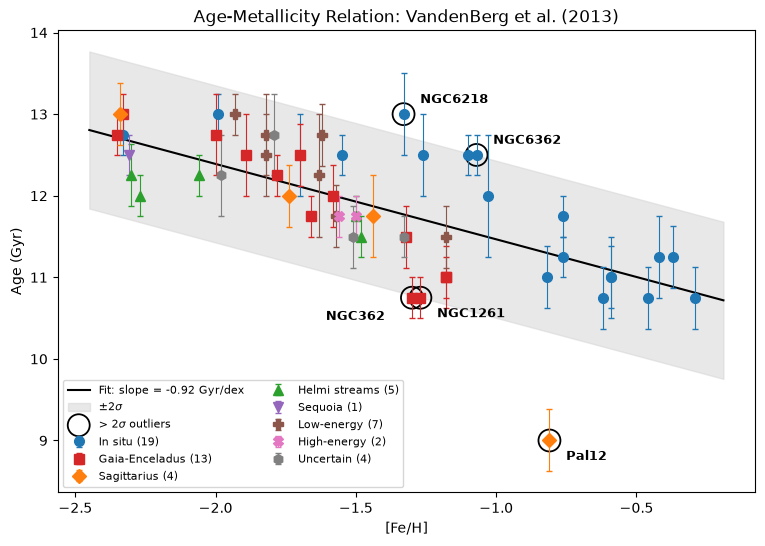

In [ ]:
# Plot age against metallicity for VandenBerg, with age errors, coloured by cluster type

plt.figure(figsize=(9,6))

# Fitted AMR and 2-sigma band
x_fit = np.linspace(FeH.min() - 0.1, FeH.max() + 0.1, 100)
plt.plot(x_fit, a_V * x_fit + b_V, "k-", label=f"Fit: slope = {a_V:.2f} Gyr/dex")
plt.fill_between(x_fit, a_V * x_fit + b_V - 2 * sigma_V, a_V * x_fit + b_V + 2 * sigma_V,
                 color="lightgrey", alpha=0.5, label="$\\pm 2\\sigma$")

# Clusters, by type
for t, (col, mk) in style.items():
    sub = data[data["Type"] == t]
    if len(sub) > 0:
        plt.errorbar(sub["FeH"], sub["Age"], yerr=sub["Age_err"], fmt=mk, color=col,
                     ms=7, elinewidth=0.8, capsize=2, label=f"{t} ({len(sub)})")

# Circle and label the outliers
plt.scatter(Cand_1["FeH"], Cand_1["Age"], s=250, facecolors="none", edgecolors="k",
            linewidths=1.3, label="> 2$\\sigma$ outliers")
for i, row in Cand_1.iterrows():
    offset = label_pos.get(row["Cluster_ID"], (12, -14 if row["resid_V"] < 0 else 8))
    plt.annotate(row["Cluster_ID"], (row["FeH"], row["Age"]), xytext=offset,
                 textcoords="offset points", fontsize=9, weight="bold")

plt.xlabel(feh_label)
plt.ylabel(age_label)
plt.title("Age-Metallicity Relation: VandenBerg et al. (2013)")
plt.legend(fontsize=8, loc="lower left", ncol=2)

plt.show()

## Plot 2: Krause et al. (2016)

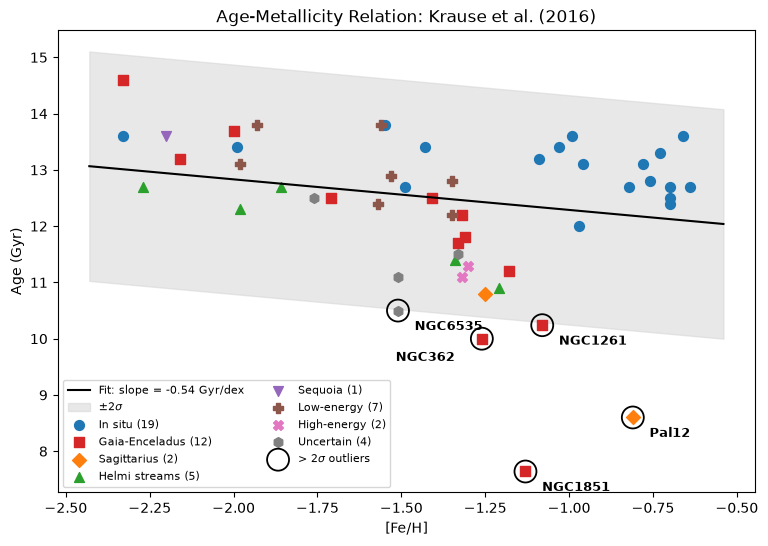

In [ ]:
# Plot age against metallicity for Krause, coloured by cluster type. Krause gives no age errors.

plt.figure(figsize=(9,6))

# Fitted AMR and 2-sigma band
x_fit = np.linspace(krause["FeH_Krause"].min() - 0.1, krause["FeH_Krause"].max() + 0.1, 100)
plt.plot(x_fit, a_K * x_fit + b_K, "k-", label=f"Fit: slope = {a_K:.2f} Gyr/dex")
plt.fill_between(x_fit, a_K * x_fit + b_K - 2 * sigma_K, a_K * x_fit + b_K + 2 * sigma_K,
                 color="lightgrey", alpha=0.5, label="$\\pm 2\\sigma$")

# Clusters, by type
for t, (col, mk) in style.items():
    sub = krause[krause["Type"] == t]
    if len(sub) > 0:
        plt.scatter(sub["FeH_Krause"], sub["Age_Krause"], marker=mk, color=col, s=50,
                    label=f"{t} ({len(sub)})")

# Circle and label the outliers
plt.scatter(Cand_2["FeH_Krause"], Cand_2["Age_Krause"], s=250, facecolors="none", edgecolors="k",
            linewidths=1.3, label="> 2$\\sigma$ outliers")
for i, row in Cand_2.iterrows():
    offset = label_pos.get(row["Cluster_ID"], (12, -14 if row["resid_K"] < 0 else 8))
    plt.annotate(row["Cluster_ID"], (row["FeH_Krause"], row["Age_Krause"]), xytext=offset,
                 textcoords="offset points", fontsize=9, weight="bold")

plt.xlabel(feh_label)
plt.ylabel(age_label)
plt.title("Age-Metallicity Relation: Krause et al. (2016)")
plt.legend(fontsize=8, loc="lower left", ncol=2)

plt.show()

In [ ]:
# Locate young, metal-rich clusters, i.e. younger than 11 Gyr in either dataset with [Fe/H] > -1.0.
# Note: the three in situ clusters selected here (NGC5927, NGC6352, NGC6496) lie on the in situ (disc) branch
# of the AMR, as expected for metal-rich clusters; only Pal12 sits on the younger, accreted branch.
Cand_4 = data[((data["Age"] < 11) | (data["Age_Krause"] < 11)) & (data["FeH"] > -1.0)]

print(Cand_4[["Cluster_ID", "Type", "FeH", "Age", "Age_Krause"]])

   Cluster_ID         Type   FeH    Age  Age_Krause
16    NGC5927      In situ -0.29  10.75        12.7
27    NGC6352      In situ -0.62  10.75        12.7
31    NGC6496      In situ -0.46  10.75        12.4
53      Pal12  Sagittarius -0.81   9.00         8.6


In [ ]:
# Group all candidates into a single list, and count how many lists each cluster appears in.
Candidates = [Cand_1["Cluster_ID"], Cand_2["Cluster_ID"], Cand_4["Cluster_ID"]]

counts = pd.concat(Candidates).value_counts()
summary = pd.DataFrame({"Count": counts, "Type": data.set_index("Cluster_ID").loc[counts.index, "Type"]})
summary

,Count,Type
Cluster_ID,,
Pal12,3,Sagittarius
NGC362,2,Gaia-Enceladus
NGC1261,2,Gaia-Enceladus
NGC1851,2,Gaia-Enceladus
NGC6535,2,Uncertain
NGC6218,1,In situ
NGC6362,1,In situ
NGC6304,1,In situ
NGC6366,1,In situ
